<a href="https://colab.research.google.com/github/Aditigk1203/ADITI-G-KRISHNAN/blob/main/EDA_phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
# LOAD DATASET

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Saving stars_type.csv to stars_type.csv
Dataset shape: (240, 7)

First 5 rows:


,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.0024,0.1700,16.12,0,Red,M
1,3042,0.0005,0.1542,16.60,0,Red,M
2,2600,0.0003,0.1020,18.70,0,Red,M
3,2800,0.0002,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    object 
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              237 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(2), int64(2), object(3)
memory usage: 13.3+ KB


In [ ]:
# Clean names of columns
df.columns = df.columns.str.strip()

# Convertin lum into numeric
df["Luminosity(L/Lo)"] = pd.to_numeric(
    df["Luminosity(L/Lo)"], errors="coerce"
)

# Filling missing
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# missing categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:", df.isnull().sum().sum())



Missing values after cleaning: 0


In [ ]:
#PRINCIPAL COMPONENT ANALYSIS (PCA)

# numerical features only, excluding the target
X_pca = df.drop(columns=["Star type"]).select_dtypes(
    include=np.number
)

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)


In [ ]:
# Reduce features
pca = PCA(n_components=2)
X_pca_result = pca.fit_transform(X_scaled)

In [ ]:
pca_df = pd.DataFrame(
    X_pca_result,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Star type"] = df["Star type"].values

In [ ]:
print("\nOriginal number of numerical features:", X_pca.shape[1])
print("Number of principal components:", pca.n_components_)

print("\nExplained variance ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print(
    "Total variance retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2), "%"
)

print("\nFirst 5 PCA results:")
display(pca_df.head())


Original number of numerical features: 4
Number of principal components: 2

Explained variance ratio:
PC1: 60.14 %
PC2: 23.5 %
Total variance retained: 83.65 %

First 5 PCA results:


,Principal Component 1,Principal Component 2,Star type
0,1.470709,-0.359622,0
1,1.498300,-0.360876,0
2,1.630877,-0.394970,0
3,1.509829,-0.381858,0
4,1.730269,-0.449730,0


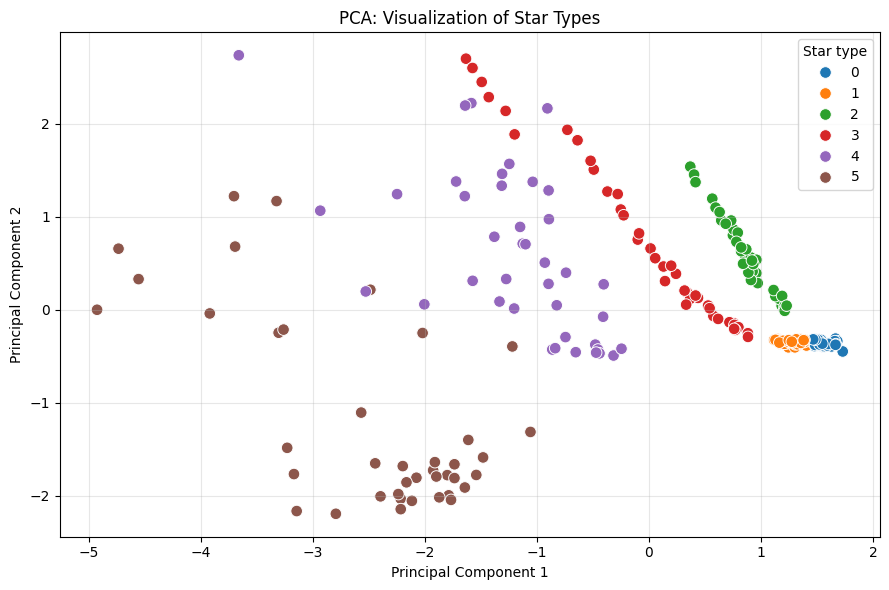

In [ ]:
# Visualize PCA results
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Star type",
    palette="tab10",
    s=70
)
plt.title("PCA: Visualization of Star Types")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#CLASSIFICATION USING RANDOM FOREST

X = df.drop(columns=["Star type"])
y = df["Star type"]

# Convert categorical numerical
X = pd.get_dummies(X, drop_first=False)

In [ ]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])



Training samples: 192
Testing samples: 48


In [ ]:
# Train
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Predict star types
y_pred = model.predict(X_test)

In [ ]:
# accuracy
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print("Classification Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00         8
           5       1.00      1.00      1.00         8

    accuracy                           1.00        48
   macro avg       1.00      1.00      1.00        48
weighted avg       1.00      1.00      1.00        48



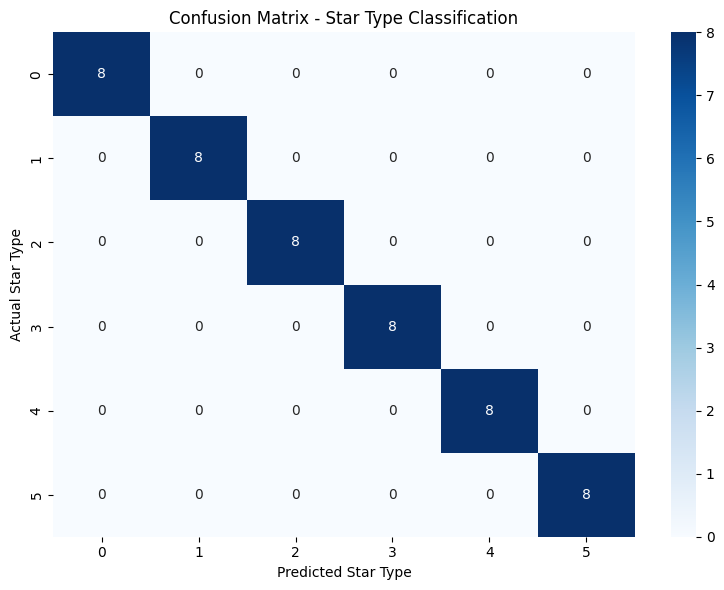

In [ ]:

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Star Type Classification")
plt.xlabel("Predicted Star Type")
plt.ylabel("Actual Star Type")
plt.tight_layout()
plt.show()



In [ ]:
# Display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 10 Important Features:")
display(importance.head(10).to_frame("Importance"))


Top 10 Important Features:


,Importance
Absolute magnitude(Mv),0.255058
Radius(R/Ro),0.243599
Luminosity(L/Lo),0.182373
Temperature (K),0.107994
Star color_Red,0.058189
Spectral Class_O,0.037507
Spectral Class_M,0.030735
Star color_Blue-white,0.019717
Spectral Class_B,0.014632
Star color_Blue,0.013666


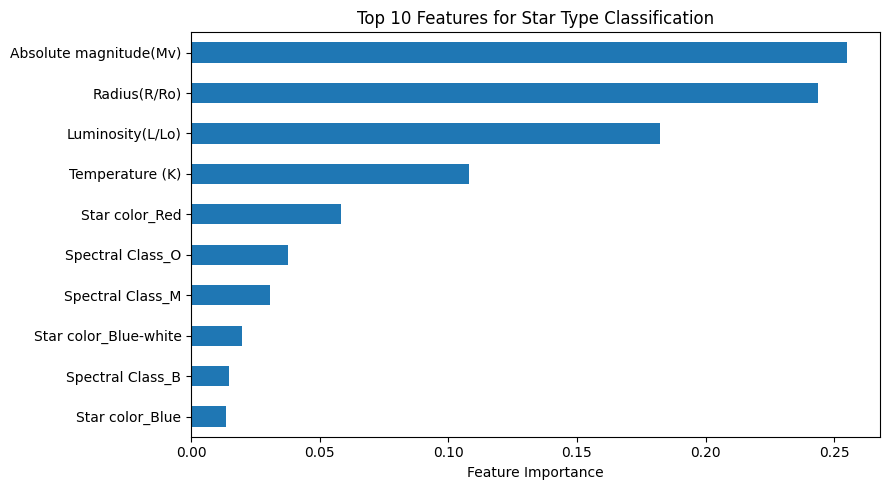

In [ ]:
plt.figure(figsize=(9, 5))
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Features for Star Type Classification")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()